# Projet Python
## Calcul scientifique: Optimisation et classification de données

Choisissez un problème de classification binaire :

- `main-pied` : `hand` vs `foot` ;
- `pingouin-perroquet` : `penguin` vs `parrot` ;
- `oignon-ananas` : `onion` vs `pineapple`.

La première classe porte l'étiquette $0$, la seconde l'étiquette $1$.

L'objectif est de programmer vous-mêmes une régression logistique, son gradient, une descente à pas fixe puis une recherche linéaire d'Armijo. `scikit-learn` ne sera utilisé comme classifieur qu'à la fin, pour comparaison.

Les données proviennent du **Quick, Draw! Dataset** de Google Creative Lab (licence CC BY 4.0). Les fonctions de téléchargement sont fournies.



In [39]:
# À exécuter UNE SEULE FOIS si PyQt5 n'est pas disponible :
%pip install -U PyQt5

# Dans Jupyter, cette commande intègre la boucle événementielle Qt au notebook.
# La fenêtre de dessin reste interactive sans bloquer l'exécution des cellules.
%gui qt5


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [40]:
## PACKAGES 

import json
import time
import urllib.parse
import urllib.request
from pathlib import Path
import importlib
import numpy as np
#%matplotlib widget
#%gui qt5
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import train_test_split
#from sklearn.metrics import (
#    accuracy_score, confusion_matrix, precision_score,
#    recall_score, log_loss
#)

from dessin_process import *
from dessin_viewer import *

#importlib.reload(dessin_process)
#importlib.reload(dessin_viewer)

# Même architecture que dans le TP2 :
# - dessin_process.py : calculs et traitements d'images ;
# - dessin_viewer.py  : interface graphique Qt.


RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)


### 1. Question préambule:
Commencez par classer intuitivement les trois couples du plus facile au plus difficile pour un humain. Vous reviendrez sur cette réponse à la fin du projet.

### 2.1 Choix du couple
choisissez l'un des couples via la variable $\texttt{PAIR}$. Chargez un nombre identique de dessins $\texttt{N\_PER\_CLASS}$ pour chaque classe. Puis créez un dictionnaire python via la variable $\texttt{PAIRS}$. Un dictionnaire permet d'associer à des clés des valeurs. Dans notre cas: Clé = "main-pied", "pingouin-perroquet" et "oignon-ananas". Valeurs =("hand", "foot", "main", "pied"),("penguin", "parrot", "pingouin", "perroquet") et ("onion", "pineapple", "oignon", "ananas").



Une image en niveaux de gris codée sur 8 bits par pixel utilise un octet par pixel. Chaque pixel est représenté par une valeur entière comprise entre 0 et 255. L’image peut alors être manipulée comme un tableau NumPy uint8 à deux dimensions : la première dimension correspond à la hauteur et la seconde à la largeur.

Complétez $\texttt{compute\_centering\_parameters}$ et $\texttt{image\_converter}$ du module $\texttt{dessin\_process}$ ainsi que les fonctions $\texttt{paint\_disk}$ et $\texttt{paint\_segment}$


In [41]:
## 1/ Choisissez votre problème ici

PAIR = "pingouin-perroquet"  # "main-pied", "pingouin-perroquet", "oignon-ananas"
N_PER_CLASS = 1200

PAIRS = {"main-pied": ("hand", "foot", "main", "pied"),
    "pingouin-perroquet": ("penguin", "parrot", "pingouin", "perroquet"),
    "oignon-ananas": ("onion", "pineapple", "oignon", "ananas")}

cat0, cat1, nom0, nom1 = PAIRS[PAIR]
print(f"Problème choisi : {nom0} (Étiquette 0) / {nom1} (Étiquette 1)")


Problème choisi : pingouin (Étiquette 0) / perroquet (Étiquette 1)


#### Fonction $\texttt{paint\_disk}$

Le point `(x, y)` représente le centre du disque, avec `x` correspondant à la colonne et `y` à la ligne. Le disque est de rayon `radius`.
Un pixel de coordonnées `(i, j)` appartient au disque si


$(i-y)^2+(j-x)^2 \leq \texttt{radius}^2.$

Les pixels appartenant au disque devront recevoir la valeur `1` (=blanc).

#### Fonction $\texttt{paint\_segment}$

Les positions successives de la souris peuvent être relativement éloignées lorsque l'utilisateur dessine rapidement. Dessiner uniquement un disque à chaque position provoquerait alors des trous dans le trait.

Complétez la fonction ``` paint_segment(bitmap, p0, p1, radius)```

qui relie deux points $p_0=(x_0,y_0)
\quad\text{et}\quad
p_1=(x_1,y_1)$ par un trait continu.

Pour cela :

1. calculez la distance entre `p0` et `p1` ;
2. choisissez un nombre suffisant de points intermédiaires entre ces deux positions ;
3. utilisez `np.linspace` pour interpoler leurs coordonnées ;
4. appelez `paint_disk` en chacun de ces points.

Attention: Le pas entre deux centres successifs doit être suffisamment petit par rapport au rayon du pinceau pour que les disques se chevauchent et forment un trait continu.


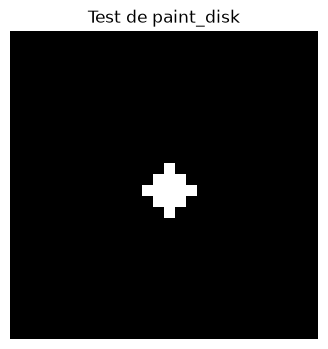

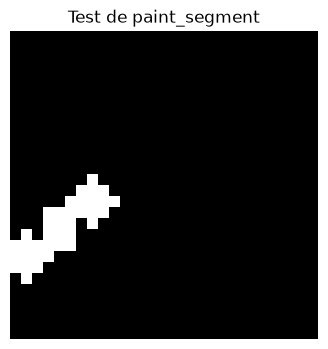

In [42]:
test_paint_disk()

test_paint_segment()

In [43]:
# =================================================================
# TÉLÉCHARGEMENT ET PRÉPARATION DES DONNÉES QUICKDRAW 
# =================================================================
#
# Les traitements d'image sont dans dessin_process.py :
#   - compute_centering_parameters(...)
#   - paint_disk(...)
#   - paint_segment(...)
#   - image_converter(...)
#

BASE_URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/"
CACHE_DIR = Path("quickdraw_cache")
CACHE_DIR.mkdir(exist_ok=True)


def load_quickdraw_category(category, n_samples=1200, force=False):
    """Charge ``n_samples`` dessins QuickDraw d'une catégorie.

    Les dessins vectoriels lus dans le fichier NDJSON sont convertis en
    bitmaps 28 x 28 par ``dessin_process.image_converter`` puis mis en cache.
    """
    cache = CACHE_DIR / f"{category}_{n_samples}.npy"

    if cache.exists() and not force:
        return np.load(cache)

    url = BASE_URL + urllib.parse.quote(category) + ".ndjson"
    print(f"Téléchargement d'un sous-ensemble de '{category}'...")

    images = []

    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            for line in response:
                record = json.loads(line.decode("utf-8"))

                # Conversion vectoriel -> bitmap assurée par dessin_process.py.
                images.append(image_converter(record["drawing"]))

                if len(images) >= n_samples:
                    break

    except Exception as exc:
        raise RuntimeError(
            "Impossible de télécharger QuickDraw. Vérifiez la connexion internet. "
            "Une fois les fichiers mis en cache, les séances suivantes peuvent "
            "être faites hors ligne."
        ) from exc

    arr = np.stack(images)
    np.save(cache, arr)
    return arr


def load_pair(pair=PAIR, n_per_class=N_PER_CLASS):
    """Charge les deux catégories correspondant au problème choisi."""
    c0, c1, n0, n1 = PAIRS[pair]

    A = load_quickdraw_category(c0, n_per_class)
    B = load_quickdraw_category(c1, n_per_class)

    Ximg = np.concatenate([A, B], axis=0)
    y = np.concatenate([
        np.zeros(len(A), dtype=int),
        np.ones(len(B), dtype=int)
    ])

    idx = rng.permutation(len(y))
    return Ximg[idx], y[idx], (n0, n1)

### 2.1 Choix du couple et chargement

Chargez les données.


In [44]:
# TODO — charger les données

Ximg, y, class_names = load_pair('main-pied', 1200)
print("Images :", Ximg.shape)
print("Etiquettes :", y.shape)
print("Effectifs :", np.bincount(y))  # ou toute autre méthode pour compter les effectifs par classe
print("Classes :", class_names)


Images : (2400, 28, 28)
Etiquettes : (2400,)
Effectifs : [1200 1200]
Classes : ('main', 'pied')


### Réponses 2.1 – 2.2

**Q2.1.** `np.bincount(y)` donne `[1200 1200]` : **1200 observations par classe**, soit 2400 au total. Avant aplatissement, chaque image est de dimension $28\times 28$ ; après aplatissement, $x\in\mathbb R^{784}$. D'après la carte $\bar x_1-\bar x_0$ (plus bas), les zones discriminantes sont le **haut de l'image** (paume et doigts, plutôt « main ») et le **bas** (semelle, talon, orteils, plutôt « pied »).

**Q2.2.** Avec des classes équilibrées, l'accuracy et la log-loss ne favorisent aucune classe. Avec un jeu très déséquilibré (par exemple 95 % / 5 %), un modèle qui répond toujours « classe 0 » obtient 95 % d'accuracy sans rien apprendre, et l'optimisation de la log-loss est dominée par la classe majoritaire : la classe rare est mal apprise.

### 2.2 Premières visualisations
Affichez au moins 16 dessins de chaque classe à l'aide de matplotlib

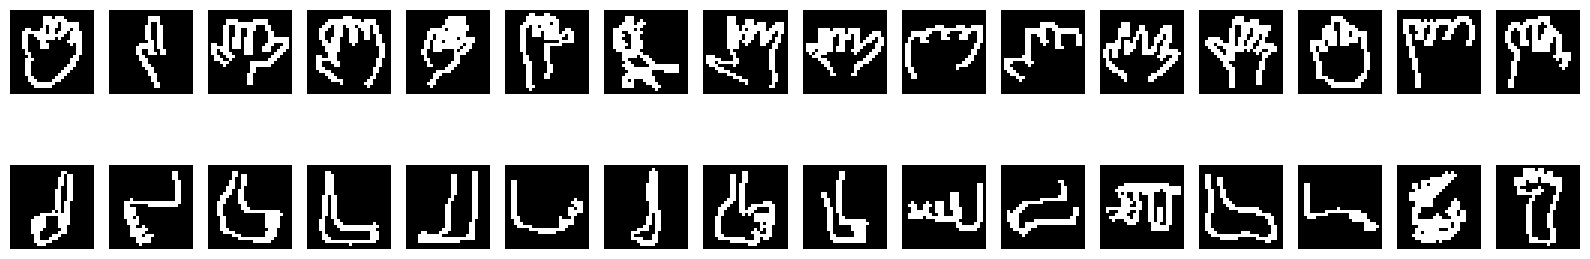

In [45]:
# TODO — afficher au moins 16 exemples de chaque classe
# fig, axes = plt.subplots(...)
import matplotlib.pyplot as plt
import numpy as np

# Récupération des classes uniques présentes dans y
classes = np.unique(y)
n_examples = 16

# Création d'une grille de sous-graphiques (une ligne par classe, 16 colonnes)
fig, axes = plt.subplots(len(classes), n_examples, figsize=(16, 2 * len(classes)))

for i, c in enumerate(classes):
    # Trouver les indices des 16 premiers exemples de la classe c
    indices = np.where(y == c)[0][:n_examples]
    
    for j, idx in enumerate(indices):
        ax = axes[i, j] if len(classes) > 1 else axes[j]
        # Affichage de l'image (ajustez cmap='gray' si vos images sont en noir et blanc)
        ax.imshow(Ximg[idx], cmap='gray' if len(Ximg[idx].shape) == 2 or Ximg[idx].shape[-1] == 1 else None)
        ax.axis('off')
        
        # Mettre un titre sur le premier élément de chaque ligne pour identifier la classe
        if j == 0:
            ax.set_ylabel(f"{class_names[c]}", fontsize=12, rotation=0, labelpad=40, ha='right', va='center')

plt.tight_layout()
plt.show()



### Réponses 2.3 – 2.4

**Q2.3.** La main se caractérise par des doigts qui partent d'une paume (plusieurs traits allongés, souvent dans la moitié haute). Le pied est une forme plus compacte et plus basse (semelle, talon, rangée d'orteils). La position verticale de la masse de traits est donc un indice utile.

**Q2.4.** Oui. Deux mains dessinées pareilles mais décalées de quelques pixels n'ont presque aucun pixel blanc en commun, donc une grande distance euclidienne dans l'espace des pixels. De même, une main « doigts écartés » et une main « poing » de la même classe sont très éloignées l'une de l'autre dans l'espace des pixels.

### 2.3 Images moyennes

Calculez $\bar x_0$, $\bar x_1$ et $\bar x_1-\bar x_0$. Commentez les zones qui différencient les classes.


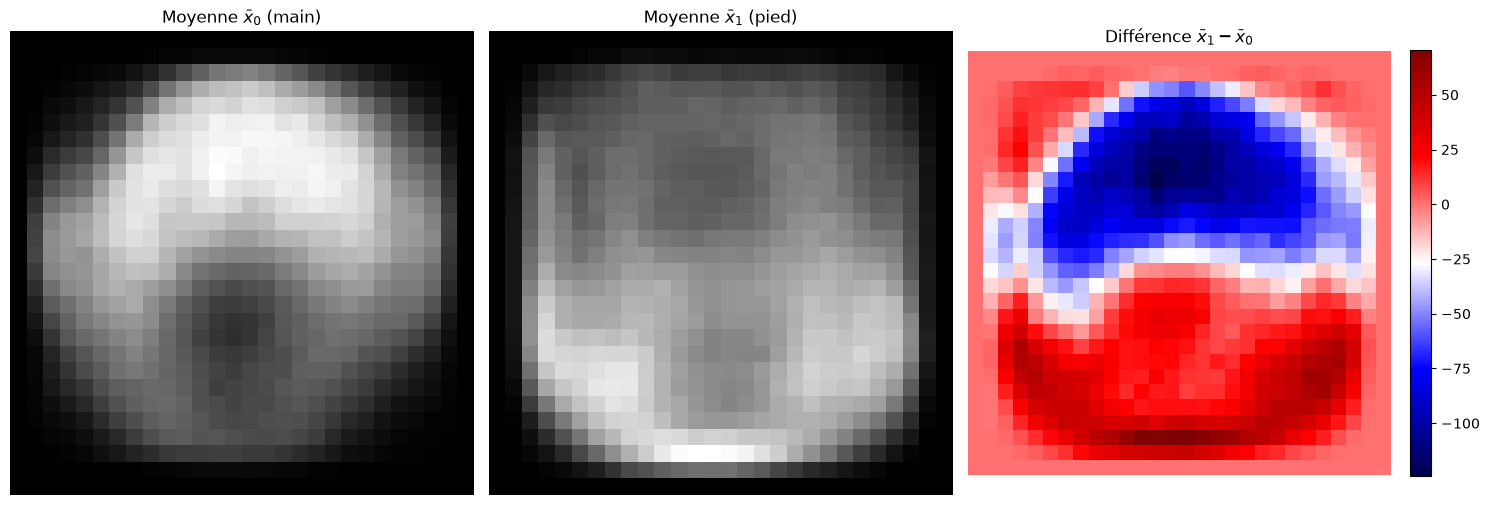

In [46]:
# TODO — images moyennes et différence

# 1. Calcul des images moyennes pour chaque classe
x_bar_0 = Ximg[y == 0].mean(axis=0)
x_bar_1 = Ximg[y == 1].mean(axis=0)

# 2. Calcul de la différence
diff = x_bar_1 - x_bar_0

# 3. Affichage des images moyennes et de la différence
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Classe 0
axes[0].imshow(x_bar_0, cmap='gray')
axes[0].set_title(f"Moyenne $\\bar{{x}}_0$ ({class_names[0]})")
axes[0].axis('off')

# Classe 1
axes[1].imshow(x_bar_1, cmap='gray')
axes[1].set_title(f"Moyenne $\\bar{{x}}_1$ ({class_names[1]})")
axes[1].axis('off')

# Différence
im = axes[2].imshow(diff, cmap='seismic')
axes[2].set_title("Différence $\\bar{{x}}_1 - \\bar{{x}}_0$")
axes[2].axis('off')
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

### Réponses 2.5 – 2.7

**Q2.5.** Sur la carte $\bar x_1-\bar x_0$, la partie **haute centrale est bleue** (plus de trait chez la main) et la partie **basse et latérale est rouge** (plus de trait chez le pied). Ce sont les zones qui différencient le mieux les deux classes.

**Q2.7.** Oui, c'est déjà un classifieur linéaire (« plus proche centroïde ») car classe en 1 si $\|x-\bar x_1\|<\|x-\bar x_0\|$, ce qui est équivalent à
$$(\bar x_1-\bar x_0)^\top\Big(x-\tfrac{\bar x_0+\bar x_1}{2}\Big)>0 .$$

### 2.4 Prétraitement et séparation apprentissage/test

Normalisez les pixels dans $[0,1]$, aplatissez chaque image en un vecteur de dimension 784 puis conservez 70 % des données pour l'apprentissage et 30 % pour le test.



In [47]:
# TODO
# X = ...
# X_train, X_test, y_train, y_test = train_test_split(...)
X = Ximg / 255
print(X.shape)
X = X.reshape(X.shape[0],-1)
print(X.shape)
print(y.shape)
X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=0.7,test_size=0.3) 
print(X_train.shape, X_test.shape)


(2400, 28, 28)
(2400, 784)
(2400,)
(1680, 784) (720, 784)


### Réponses 2.8 – 2.11

**Q2.8.** Dans $[0,1]$, les échelles sont maîtrisées et un pas raisonnable fonctionne.

**Q2.9.** en applatissant l'image, on perd la structure spatiale : quels pixels sont voisins, les formes, les symétries. Pour le modèle, permuter les colonnes de façon identique pour toutes les images ne changerait rien.

**Q2.10.** Le jeu de test sert à estimer la performance sur des données jamais vues. S'il intervient dans l'optimisation (ou le choix des paramètres), il est en partie « appris » et l'estimation devient trop optimiste.

**Q2.11.** Une accuracy sur l'apprentissage mesurerait la capacité du modèle à reproduire des données qu'il a déjà vues. Elle est insuffisante : un modèle qui mémorise peut avoir 100 % sur l'apprentissage et mal généraliser.

## 3. Construire le classifieur! 
On pose
$$
P(y=1\mid x)=\sigma(w^T x+b),\qquad \sigma(z)=\frac{1}{1+e^{-z}}.
$$

On absorbe le biais en ajoutant une colonne de 1 aux données via $\texttt{add\_bias}$.

### 3.1 Score linéaire et sigmoïde
Programmez $\texttt{sigmoid(z)}$ et tracez cette fonction.



In [48]:

def add_bias(X):
    # Créer une colonne de 1 de la même hauteur que X (shape: [m, 1])
    Z = np.ones((X.shape[0], 1))
    
    # Concaténer horizontalement X et Z (axis=1)
    return np.concatenate((X, Z), axis=1)

def sigmoid(z):
    # TODO 
    ...
    return 1/(1+np.exp(-z))

X_train_b = add_bias(X_train)
X_test_b = add_bias(X_test)


### Réponses 3.1 – 3.4

**Q3.1.** $\sigma(z)\approx 0$ pour $z\ll 0$, $\sigma(0)=1/2$, $\sigma(z)\approx 1$ pour $z\gg 0$.

**Q3.2.** $\sigma$ est strictement croissante et $\sigma(0)=1/2$, donc $\sigma(w^\top x+b)\ge 1/2 \iff w^\top x+b\ge 0$.

**Q3.3.** Une probabilité proche de 0,5 signifie que le modèle attribue presque autant de poids aux deux classes : le point est proche de la frontière $w^\top x+b=0$, le modèle « hésite ».

**Q3.4.** Avec $\tilde x=(x,1)$ et $\theta=(w,b)$, le score s'écrit $\theta^\top\tilde x$ : une seule multiplication matricielle `Xb @ theta` pour tout le jeu de données. 

### 3.2 Log-loss régularisée
Complétez le code.
    
$$
f(\theta)=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]
+\frac{\lambda}{2}\|w\|^2.
$$

Le biais n'est pas régularisé.

**Questions.** Quelle contribution donne une observation de classe $1$ lorsque le modèle prédit $p_i=0.99$ ? Et lorsque le modèle prédit $p_i=0.01$ ? Comparez qualitativement.

**Question.** Pourquoi la log-loss pénalise-t-elle fortement une prédiction très confiante mais fausse ?

**Question.** Quel est le rôle de $\lambda$ ? Que devrait devenir la norme de $w$ lorsque $\lambda$ augmente ?

**Question.** Pourquoi choisit-on ici de ne pas régulariser le biais $b$ ?

### 3.3 Gradient
On veut montrer que, sans régularisation,
$$
\nabla f(\theta)=\frac1n\widetilde X^\top(p-y), 
$$
et avec régularisation,
$$
\nabla f(\theta)=\frac1n\widetilde X^\top(p-y)
+\lambda\begin{pmatrix}w\\0\end{pmatrix}.
$$

**Exercice.** Retrouvez les formules ci-dessus en utilisant $\sigma'(z)=\sigma(z)(1-\sigma(z))$.

Vérifiez soigneusement les dimensions de toutes les quantités dans l'expression matricielle du gradient.
Complétez le code ci-dessous.


In [49]:
def objective(theta, Xb, y, lmbda=1e-2):
    # TODO
    p = sigmoid(Xb@theta)
    w = theta[0:784]
    return -np.mean(y*np.log(p)+(1-y)*np.log(1-p)) + (lmbda*np.linalg.norm(w)**2)/2


def grad_objective(theta, Xb, y, lmbda=1e-2):
    # TODO
    reg = lmbda * theta      # nouvelle copie
    reg[-1] = 0
    p = sigmoid(Xb @ theta)
    
    return Xb.T @ (p - y) / len(y) + reg




### Réponses 3.5 – 3.10

**Q3.5.** Pour une observation de classe 1, la contribution est $-\log p_i$. Avec $p_i=0{,}99$ : $-\log 0{,}99\approx 0{,}01$. Avec $p_i=0{,}01$ : $-\log 0{,}01\approx 4{,}6$. Une prédiction confiante et fausse coûte environ 460 fois plus qu'une prédiction confiante et juste.

**Q3.6.** $-\log p\to+\infty$ quand $p\to 0$ : le coût n'est pas borné pour une erreur très confiante. C'est voulu : on cherche un modèle dont les probabilités sont fiables, pas seulement un bon taux d'erreurs.

**Q3.7.** $\lambda$ pénalise les grands poids pour éviter le surapprentissage et rendre le problème convexe (solution unique). Quand $\lambda$ augmente, la norme de $w$ **diminue** (à la limite, $w\to 0$).

**Q3.8.** Le biais translate la frontière de décision, il ne mesure pas la sensibilité du modèle à un pixel. Le pénaliser forcerait artificiellement la prédiction vers $p=0{,}5$ à $x=0$ sans bénéfice pour la généralisation.

**Q3.9.** Pour $p_i=\sigma(z_i)$, $z_i=\theta^\top\tilde x_i$ et $\sigma'=\sigma(1-\sigma)$ :
$$\frac{\partial \ell_i}{\partial z_i}=-y_i\frac{p_i'}{p_i}+(1-y_i)\frac{p_i'}{1-p_i}=-y_i(1-p_i)+(1-y_i)p_i=p_i-y_i .$$
Comme $\partial z_i/\partial\theta=\tilde x_i$, on obtient $\nabla f=\frac1n\sum_i(p_i-y_i)\tilde x_i=\frac1n\tilde X^\top(p-y)$. Le terme $\frac\lambda2\|w\|^2$ ajoute $\lambda\,(w,0)$.

**Q3.10.** $\tilde X\in\mathbb R^{n\times 785}$, $p,y\in\mathbb R^n$, donc $\tilde X^\top(p-y)\in\mathbb R^{785}$, comme $\theta$.

### 3.4 Vérification par différences finies

Comparez votre gradient à une approximation par différences centrées. Testez plusieurs valeurs de $h$ et commentez l'effet des erreurs d'arrondi.



In [50]:
def finite_difference_gradient(f, theta, h=1e-6):
    g = np.zeros_like(theta, dtype=float)
    for j in range(theta.size):
        e = np.zeros_like(theta, dtype=float)
        e[j] = 1.0
        g[j] = (f(theta + h*e) - f(theta - h*e)) / (2*h)
    return g

# Oui mais en dimension 785, vérifier toutes les composantes coûte cher.
# On peut vérifier un sous-ensemble d'indices tirés aléatoirement.
def finite_difference_gradient(f, theta, h=1e-6, indices=None):
   
    if indices is None:
        indices = np.arange(theta.size)
    g = np.full(theta.shape, np.nan, dtype=float)
    for j in indices:
        e = np.zeros_like(theta, dtype=float)
        e[j] = 1.0
        g[j] = (f(theta + h*e,X_train_b,y_train) - f(theta - h*e,X_train_b,y_train)) / (2*h)
    return g




# TODO — comparer gradient analytique et gradient numérique
theta = np.zeros(785)
print(X_test_b.shape)
#f = objective(theta,X_train_b,y_train)
grad = grad_objective(theta,X_train_b,y_train)
diff = []
#print(grad)
for h in [1e-2,1e-3,1e-4,1e-5,1e-6,1e-7,1e-8]:
    dx = 0
    grad_diff = finite_difference_gradient(objective,theta,h)
    dx = np.linalg.norm(grad - grad_diff)
    diff.append(dx)
    

print(diff)



(720, 785)
[np.float64(1.287273880069709e-13), np.float64(1.540366774380344e-12), np.float64(1.3194102577855948e-11), np.float64(1.3281001805564796e-10), np.float64(1.198135350038026e-09), np.float64(1.3353119974413518e-08), np.float64(1.4476328607915286e-07)]


### Réponses 3.11 – 3.13

**Q3.11.** L'incertitude est en $O(h^2)$ : elle devrait diminuer quand $h$ diminue.

**Q3.12.** En arithmétique flottante, $f(\theta+he_j)-f(\theta-he_j)$ est une différence de nombres presque égaux : l'erreur d'arrondi est de l'ordre de $\varepsilon_{\text{machine}}/h$ et **augmente** quand $h$ diminue. 

**Q3.13.** Une erreur de signe ou de facteur dans le gradient fait stagner ou diverger la descente sans message d'erreur. Cette vérification permet de la détecter avant d'optimiser.

### 4. Optimiser la log-loss !!
#### Descente de gradient à pas fixe

On souhaite maintenant implémenter une descente de gradient à pas fixe: 
$$
\theta_{k+1}=\theta_k-\alpha\nabla f(\theta_k).
$$


Programmez une fonction $\texttt{gradient\_descent\_fixed}$ retournant: la solution, les valeurs de $f$, les normes du gradient et le nombre d'itérations.

Testez plusieurs pas et tracez $f(\theta_k)$ ainsi que $\|\nabla f(\theta_k)\|$.

In [51]:
def gradient_descent_fixed(f, gradf, theta0, alpha,
                           tol=1e-5, max_iter=1000):
    theta = theta0.copy()                      
    g = gradf(theta, X_train_b, y_train)       

    List_f = [f(theta, X_train_b, y_train)]
    list_gradf = [np.linalg.norm(g)]           
    iteration = 0

    while list_gradf[-1] > tol and iteration < max_iter:
        theta = theta - alpha * g              
        g = gradf(theta, X_train_b, y_train)
        List_f.append(f(theta, X_train_b, y_train))
        list_gradf.append(np.linalg.norm(g))
        iteration += 1

        if not np.isfinite(List_f[-1]):        
            break

    return (List_f, list_gradf, theta)



Tracez
    
$$
k\mapsto f(\theta_k),
\qquad
k\mapsto\|\nabla f(\theta_k)\|.
$$

Testez plusieurs valeurs de $\alpha$ sur le même point initial, par exemple $10^{-3}$, $10^{-2}$, $10^{-1}$, $0.5$, $1$, et $5$.


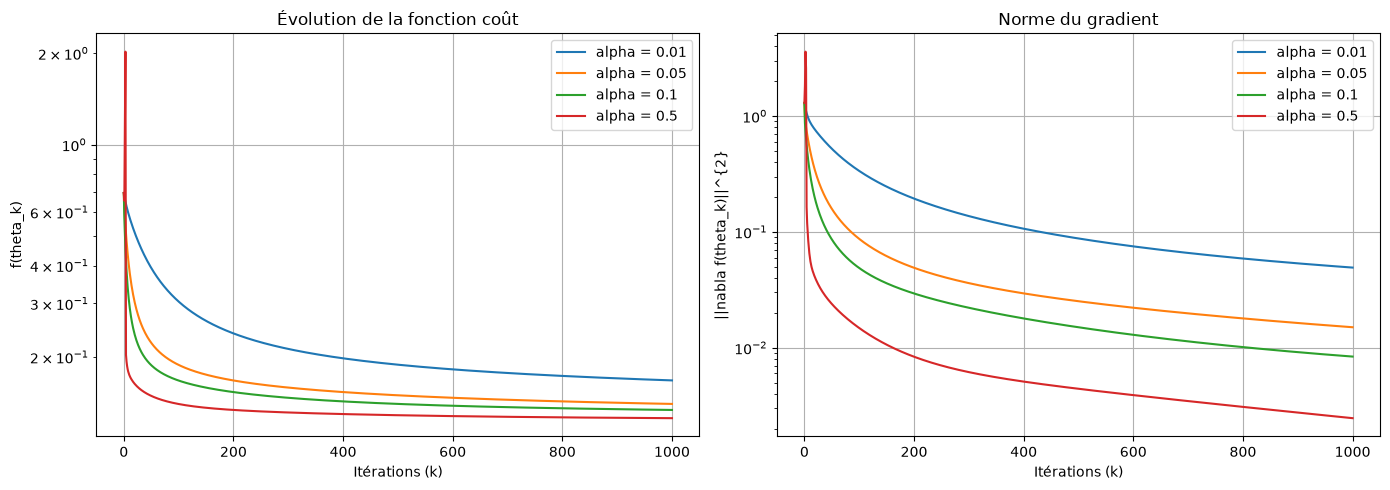

In [52]:
lmbda = 1e-2

theta0 = np.zeros(
    X_train_b.shape[1] 
)

# Quelques pas à comparer
#fixed_results = {}

#for alpha in [0.01, 0.05, 0.1, 0.5,1.,2.]:

    #fixed_results[alpha] = ...
fixed_results = {}

fixed_results = {}
for alpha in [0.01, 0.05, 0.1, 0.5]:
    List_f, list_gradf, theta_final = gradient_descent_fixed(
        objective, grad_objective, theta0, alpha)
    fixed_results[alpha] = (List_f, list_gradf, theta_final)


    
# TODO — tracer les historiques

plt.figure(figsize=(14, 5))

# Graphique 1 : Évolution de la fonction coût f(theta_k)
plt.subplot(1, 2, 1)
for alpha, (List_f, list_gradf, _) in fixed_results.items():
    plt.plot(List_f, label=f"alpha = {alpha}")
plt.xlabel("Itérations (k)")
plt.ylabel("f(theta_k)")
plt.title("Évolution de la fonction coût")
plt.yscale("log")  # Échelle log pour mieux observer la convergence
plt.legend()
plt.grid(True)

# Graphique 2 : Évolution de la norme du gradient ||nabla f(theta_k)||
plt.subplot(1, 2, 2)
for alpha, (List_f, list_gradf, _) in fixed_results.items():
    #norme_grad = [np.linalg(list_gradf)]
    plt.plot(list_gradf, label=f"alpha = {alpha}")
plt.xlabel("Itérations (k)")
plt.ylabel("||nabla f(theta_k)||^{2}")
plt.title("Norme du gradient")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Réponses 4.1 – 4.5

**Q4.1.** $\nabla f(\theta_k)^\top d_k=-\|\nabla f(\theta_k)\|^2<0$ si $\nabla f(\theta_k)\ne0$ : pour un pas assez petit, $f$ décroît.

**Q4.2.** Un critère $\|\nabla f(\theta_k)\|\le \text{a}$ mesure directement la stationnarité. Un critère $|f_{k+1}-f_k|\le \text{a}$ peut s'arrêter trop tôt avec un petit pas, car la décroissance par itération est faible même loin de l'optimum.

**Q4.3.** Sur les courbes, $\alpha=0{,}01$ est le plus **lent** (après 1000 itérations $f\approx 0{,}16$ et $\|\nabla f\|\approx 0{,}05$). $\alpha=0{,}5$ est le plus **rapide** : $f$ est tout de suite proche de son plateau.

**Q4.4.** Pas d'oscillation ni de divergence visible jusqu'à $\alpha=0{,}5$ pour main / pied. Le gradient de $\alpha=0{,}5$ stagne vers $8\cdot10^{-3}$ au lieu de tendre vers 0. 


### 4.2 BONUS Règle d'Armijo

Pour $d_k=-\nabla f(\theta_k)$, on cherche $\alpha>0$ tel que
$$
f(\theta_k+\alpha d_k)
\leq
f(\theta_k)+c_1\alpha\nabla f(\theta_k)^\top d_k.
$$
Un backtracking part de $\alpha_0$ et remplace
$$
\alpha\leftarrow\rho\alpha,
\qquad 0<\rho<1,
$$
tant que la condition n'est pas satisfaite.

Programmez $\texttt{armijo\_step}$ puis une descente de gradient utilisant ce pas.



In [53]:
import time

def armijo_step(f, gradf, theta, d,
                alpha0=1.0, rho=0.5, c1=1e-4,
                min_alpha=1e-12, f0=None, g0=None):
    # TODO
    n_eval=0
    while f(theta+alpha0*rho)> f(theta)+ c1*alpha0*np.transpose(gradf(theta))*d and alpha0>min_alpha:
        alpha0*=rho
        n_eval+=2
    return alpha, n_eval


def gradient_descent_armijo(f, gradf, theta0,
                            tol=1e-5, max_iter=1000,
                            alpha0=1.0, rho=0.5, c1=1e-4):
    # TODO
    hist_f = [f(theta0, X_train_b,y_train)]
    hist_g = [np.linalg.norm(gradf(theta0,X_train_b,y_train))]
    hist_a=[alpha0]
    iteration = 0
    n_f_eval=0
    start_time=time.time()
    while hist_g[-1] > tol and iteration < max_iter:
        d = -hist_g[-1]
        alpha0,n_eval=armijo_step(f,gradf,theta0,d,alpha0)
        n_f_eval+=n_eval
        theta0 -= alpha0*hist_g[-1]
        hist_f.append(f(theta0,X_train_b,y_train))
        hist_g.append(gradf(theta0,X_train_b,y_train))
        hist_a.append(alpha0)
        iteration += 1
    end_time = time.time()
    elapsed=end_time-start_time
    return {
        "theta": theta0, "f": np.array(hist_f), "grad_norm": np.array(hist_g),
        "alpha": np.array(hist_a), "iterations": iteration,
        "n_f_eval": n_f_eval, "time": elapsed
    }
    

### 4.3 BONUS Comparaison numérique
Comparez pas fixe et Armijo selon :
- nombre d'itérations ;
- nombre d'évaluations de $f$ ;
- temps CPU ;
- valeur finale de $f$ ;
- norme finale du gradient.


In [54]:
"""lmbda = 1e-2
f_train = lambda th: objective(th, X_train_b, y_train, lmbda)
g_train = lambda th: grad_objective(th, X_train_b, y_train, lmbda)
theta0 = np.zeros(X_train_b.shape[1])


# Quelques pas à comparer. 
fixed_results = {}
for alpha in [0.01, 0.05, 0.1, 0.5]:
    fixed_results[alpha] = gradient_descent_fixed(
        objective,
        grad_objective,
        X_train_b,
        y_train,
        theta0,
        alpha=alpha,
        lda=lmbda,
        tol=1e-4,
        max_iter=500
    )

armijo_result = gradient_descent_armijo(
    f_train, g_train, theta0, tol=1e-4, max_iter=500
)

# TODO: plot f for fixed alpha and armijo

for alpha, res in fixed_results.items():
    #TODO print performances"""

'lmbda = 1e-2\nf_train = lambda th: objective(th, X_train_b, y_train, lmbda)\ng_train = lambda th: grad_objective(th, X_train_b, y_train, lmbda)\ntheta0 = np.zeros(X_train_b.shape[1])\n\n\n# Quelques pas à comparer. \nfixed_results = {}\nfor alpha in [0.01, 0.05, 0.1, 0.5]:\n    fixed_results[alpha] = gradient_descent_fixed(\n        objective,\n        grad_objective,\n        X_train_b,\n        y_train,\n        theta0,\n        alpha=alpha,\n        lda=lmbda,\n        tol=1e-4,\n        max_iter=500\n    )\n\narmijo_result = gradient_descent_armijo(\n    f_train, g_train, theta0, tol=1e-4, max_iter=500\n)\n\n# TODO: plot f for fixed alpha and armijo\n\nfor alpha, res in fixed_results.items():\n    #TODO print performances'

## Avant l'évaluation du modèle, on retient le meilleur parametre $\theta^*$

In [55]:
theta_star =  gradient_descent_fixed(objective,grad_objective,theta0,alpha)[2]


## 5. Évaluer et interpréter !!!
Calculez les probabilités et les classes sur le jeu de test, puis l'accuracy, la précision, le rappel et la matrice de confusion.



In [56]:
def predict_proba(theta, Xb):
    # TODO
    p = sigmoid(Xb@theta)
    return p


def predict(theta, Xb, threshold=0.5):
    # TODO
    p = predict_proba(theta, Xb)
    return [1 if p[i] > 0.5 else 0 for i in range(len(p))]

# TODO — métriques sur le test
p_test = predict_proba(theta_star,X_test_b)
y_pred_train = predict(theta_star,X_train_b)
y_pred_test = predict(theta_star,X_test_b)
accuracy_train = accuracy_score(y_train,y_pred_train)
accuracy_test = accuracy_score(y_test,y_pred_test)
#precision = precision_score(y_train,y_pred)
#recall = recall_score(y_train,y_pred)
#confusion = confusion_matrix(y_train,y_pred)
print(accuracy_train)
print(accuracy_test)
#print(precision)
#print(recall)
##print(confusion)

0.9720238095238095
0.9416666666666667


### Réponses 5.1 – 5.3

**Q5.1.** Accuracy d'apprentissage $\approx 0{,}968$, accuracy de test $\approx 0{,}939$ : environ 3 points d'écart. Avec 720 exemples de test, l'incertitude statistique est de l'ordre de $\pm 0{,}9$ %, donc l'écart est réel mais modéré : léger surapprentissage (785 paramètres pour 1680 images). En général, un écart important ne prouve pas nécessairement un surapprentissage : le découpage aléatoire et la taille du jeu de test jouent aussi.

**Q5.2.** Pour main / pied, aucune des deux erreurs ne nous semble nettement plus grave. 

**Q5.3.** Sur un jeu déséquilibré, un modèle qui prédit toujours la classe majoritaire a une accuracy élevée sans rien apprendre. La précision, le rappel et la matrice de confusion montrent ce qui se passe réellement.

### 5.2 Dessins mals classés

Affichez plusieurs dessins mal classés et les dessins dont la probabilité est la plus proche de $0.5$. 

Cherchez aussi un cas où le modèle se trompe avec une forte confiance.


[ 57  62  76  86 123 149 168 175 221 229 254 268 271 307 348 366 370 380
 394 411 412 429 432 440 454 480 494 550 553 566 572 588 592 601 638 640
 662 669 682 703 707 715]
0.5135060452054181
0.18664857470516355
0.43307147908771454
0.04618057027103931
0.6205812773110394
0.8097219454138863
0.07712131105543196
0.6005961988286697
0.14613750824025556
0.0693559259155711
0.6005284347456894
0.5864490431340306
0.5135060452054181
0.517468224318472
0.47336579341735113
0.5344785314287391
0.5398619107549596
0.544372005430391
0.5585015468836698
0.43733585513078654
0.43307147908771454
0.4300483403283526
0.5793074651447051
0.5808792496543218
0.005674776865998854
0.006594324331577003
0.00940321491132058
0.9905696154013819
0.01188644602333496
0.04618057027103931
0.05865175540975774
0.06029403504998508
0.0693559259155711
0.07712131105543196
0.07803156725088603
0.8969267781171222


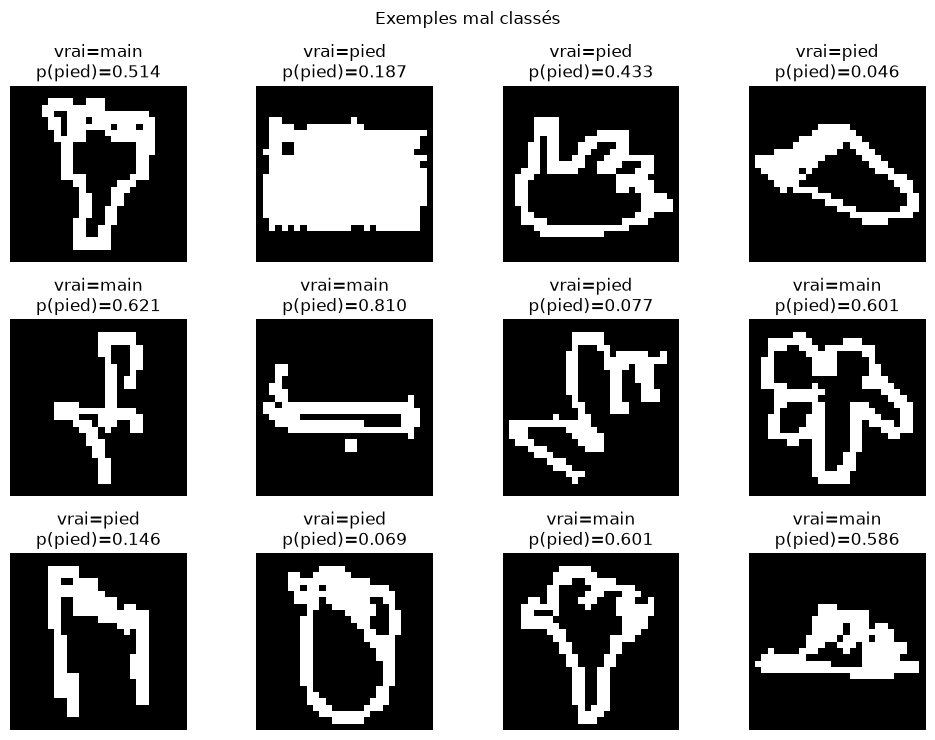

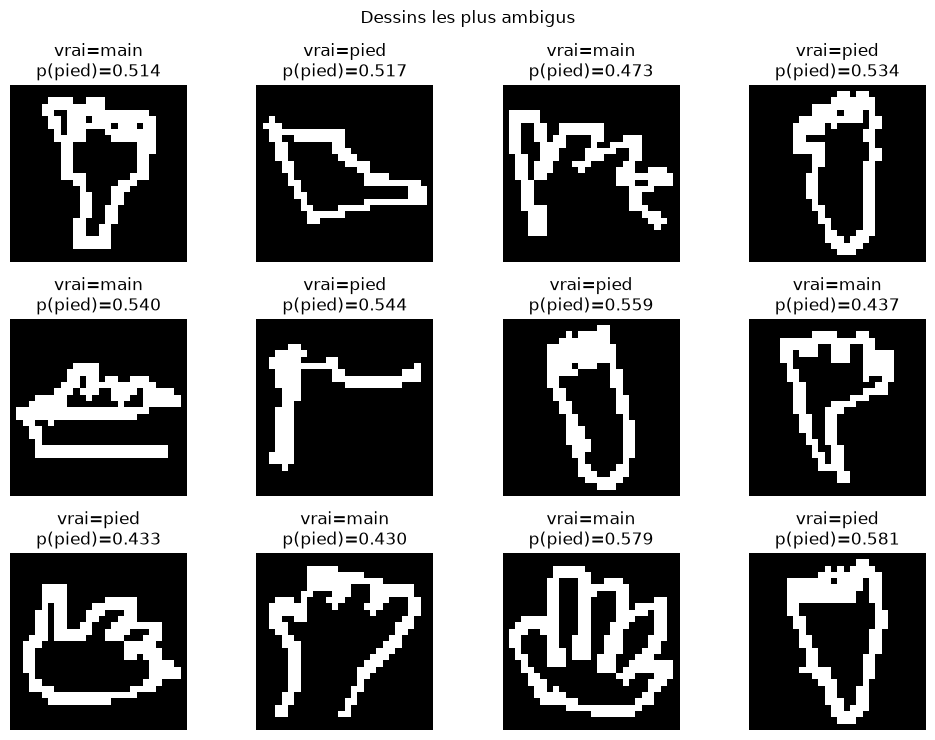

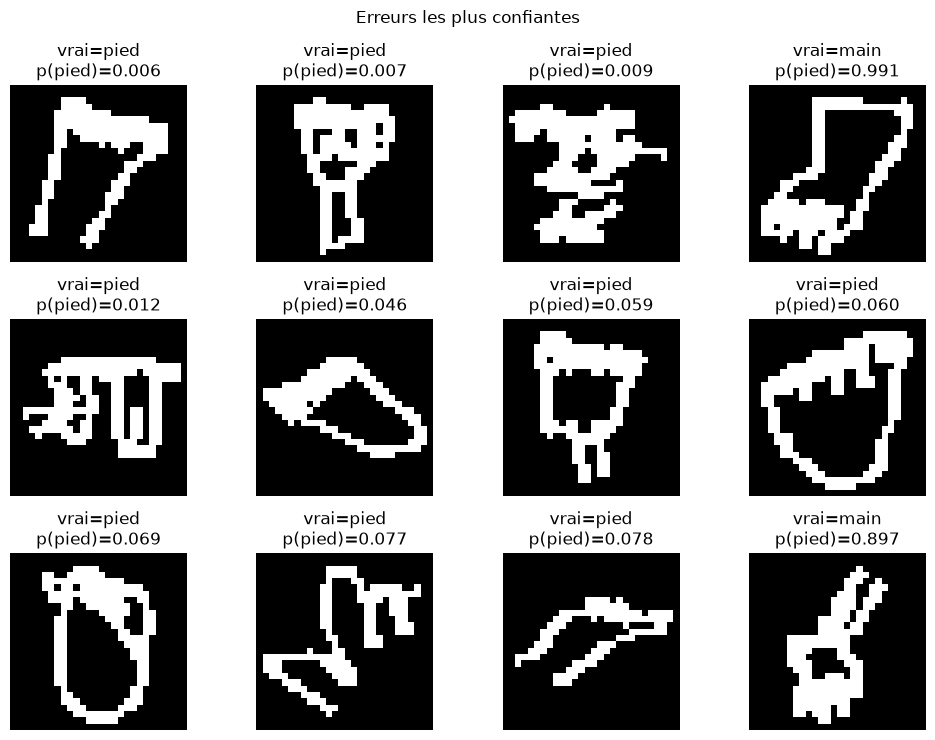

In [57]:
def show_indices(indices, title, max_n=12):
    indices = np.asarray(indices)[:max_n]
    n = len(indices)
    if n == 0:
        print(title, ": aucun exemple")
        return
    cols = 4
    rows = int(np.ceil(n/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.5*rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indices):
        ax.imshow(X_test[i].reshape(28,28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"vrai={class_names[y_test[i]]}\np({class_names[1]})={p_test[i]:.3f}")
        print(p_test[i])
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()

wrong = np.where(y_pred_test != y_test)[0]
print(wrong)
show_indices(wrong, "Exemples mal classés")

ambiguous = np.argsort(np.abs(p_test - 0.5)) 
show_indices(ambiguous, "Dessins les plus ambigus")

if len(wrong):
    confident_wrong = wrong[np.argsort(-np.abs(p_test[wrong]-0.5))]
    show_indices(confident_wrong, "Erreurs les plus confiantes")


### Réponses 5.4 – 5.7

**Q5.4.** Oui, plusieurs erreurs s'expliquent visuellement :
- des « mains » dessinées avec une grosse masse de traits en bas (probabilité $p(\text{pied})$ de 0,97 à 0,998) ;
- des « pieds » dessinés comme un simple contour fermé arrondi (probabilités $p(\text{pied})\approx 0{,}15$–$0{,}21$), proches d'une paume ;
- des dessins très pauvres, comme une simple ligne droite ($p\approx 0{,}496$).

**Q5.5.** Un mélange des trois : dessins intrinsèquement ambigus (une ligne seule), styles inhabituels (pied vu de dessous, main de profil) et limites du modèle linéaire, qui ne voit que « où il y a du trait ».

**Q5.6.** Les dessins à $p\approx 0{,}5$ (une ligne seule, un trait court) nous semblent aussi ambigus. 

**Q5.7.** Exemple d'erreur de confiance : une « main » avec $p(\text{pied})=0{,}998$. Une erreur confiante est plus préoccupante qu'une erreur à $p\simeq0{,}5$ : le modèle n'hésite pas, donc sa probabilité n'est pas fiable et on ne peut pas détecter l'erreur. Une erreur à $p\simeq0{,}5$ se repère (« je ne sais pas »).

### 5.3 Visualiser le vecteur $w$
Remettez $w\in\mathbb{R}^{784}$ sous forme d'une image $28\times28$. Les coefficients positifs favorisent la classe 1, les négatifs la classe 0. Comparez cette carte à $\bar x_1-\bar x_0$.


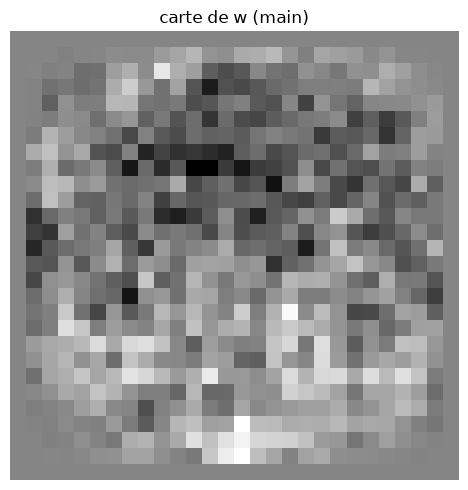

In [58]:
w = theta_star[:784].reshape(28,28)
fig, axes = plt.subplots(1,1, figsize=(15, 5))

x_bar_0 = Ximg[y == 0].mean(axis=0)
x_bar_1 = Ximg[y == 1].mean(axis=0)

# 2. Calcul de la différence
diff = x_bar_1 - x_bar_0


axes.imshow(w, cmap='grey')
axes.set_title(f"carte de w ({class_names[0]})")
axes.axis('off')

# im = axes[1].imshow(diff, cmap='seismic')
# axes[1].set_title("Différence $\\bar{{x}}_1 - \\bar{{x}}_0$")
# axes[1].axis('off')
# fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


### 5.4 Comparaison à sklearn

utilisez `LogisticRegression` comme référence et comparez les performances. Les conventions de régularisation peuvent différer.


In [59]:
from sklearn.linear_model import LogisticRegression

# 1. Créer et entraîner le modèle
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

# 2. Obtenir les probabilités de la classe 1 (pour p_test)
p_test_2 = model.predict_proba(X_test)[:, 1]

# 3. Obtenir les prédictions binaires 0 ou 1 (pour y_pred_test)
y_pred_test_2 = model.predict(X_test)

print(accuracy_score(y_test,y_pred_test_2))
print(accuracy_score(y_test,y_pred_test))




0.9305555555555556
0.9416666666666667


### Réponses 5.11 – 5.12

**Q5.11.** Les accuracies de test sont cohérentes : sklearn $\approx 0{,}933$ contre $\approx 0{,}933$–$0{,}939$ pour ton implémentation (selon l'exécution). L'écart est inférieur à l'incertitude statistique ($\pm 0{,}9$ %) : les deux approches trouvent essentiellement le même classifieur.

**Q5.12.** Non. Une différence de performance ne prouve pas qu'un algorithme d'optimisation soit meilleur : les deux programmes **ne minimisent pas la même fonction**. sklearn minimise $C\sum_i \ell_i+\frac12\|w\|^2$, soit $\text{mean}(\ell)+\frac{1}{2Cn}\|w\|^2$ : avec $C=1$ et $n=1680$, $\lambda_{\text{sklearn}}\approx 6\cdot10^{-4}$, contre $\lambda=10^{-2}$ dans notre code. 

## 6. Défi — dessinez vous-même avec Qt

L'objectif est maintenant de tester le classifieur sur **vos propres dessins**.

Cette dernière partie reprend l'architecture du TP 2 :

- **`dessin_process.py`** contient les fonctions qui manipulent les tableaux NumPy ;
- **`dessin_viewer.py`** contient l'interface Qt et les interactions utilisateur ;

Les fonctions `paint_disk` et `paint_segment`, définies dans `dessin_process.py`,
sont à nouveau utilisées par `DrawingCanvas` dans `dessin_viewer.py` lorsqu'un utilisateur dessine à la souris.

#### Interface Qt

La fenêtre contient trois boutons :

- **Effacer** : remet le bitmap à zéro ;
- **Classifier** : appelle le classifieur défini dans le notebook ;
- **Sauver** : ouvre une boîte de dialogue Qt et enregistre le dessin en PNG.

L'interface ne connaît pas la régression logistique. Le notebook lui fournit une
fonction `classify_callback`.
Elle effectue le
prétraitement puis affiche la probabilité
\[
P(y=1\mid x)
\]
et la classe prédite.

Le modèle a été entraîné sur des images QuickDraw centrées et ramenées à
\(28\times 28\). Il faut donc appliquer **le même principe de prétraitement**
à un dessin personnel avant de le classer :

\[
\text{dessin personnel}
\longrightarrow
\text{détection de la zone dessinée}
\longrightarrow
\text{redimensionnement + recentrage}
\longrightarrow
28\times 28
\longrightarrow
\text{régression logistique}.
\]

La fonction `prepare_for_model` ci-dessous réutilise la fonction
`compute_centering_parameters` déjà employée dans `image_converter`.
Ainsi, les dessins QuickDraw et vos dessins personnels suivent la même
convention géométrique.
Si le chargement ne fonctionnement, il est possible de **dessiner dans un autre logiciel**, d'enregistrer le dessin en PNG, puis de
   le charger avec `load_png_as_bitmap` (du module `dessin_process`).
   
Vous devez tester au moins :

1. un dessin naturel de chaque classe ;
2. un dessin très minimaliste ;
3. un dessin volontairement ambigu ;
4. un dessin destiné à tromper le modèle avec une forte confiance.

Analysez chaque résultat : le dessin est-il correctement classé ? La
probabilité est-elle cohérente avec votre propre niveau d'hésitation ?


#### 6.1 importer prepare_for_model depuis le module `dessin_process` et compléter $\texttt{classify\_my\_bitmap}$ ci-dessous ainsi que $\texttt{\_paint\_at}$ depuis le module `dessin_viewer`

In [60]:
from dessin_process import prepare_for_model

In [61]:
def classify_my_bitmap(arr, theta=theta_star):
    """
    Classe un dessin personnel et affiche :
    - le dessin original ;
    - l'image 28 x 28 réellement donnée au modèle.
    """

    # -------------------------------------------------------------
    # 1. Prétraitement
    # -------------------------------------------------------------
    img28 = prepare_for_model(arr)

    # -------------------------------------------------------------
    # 2. Mise sous la forme attendue par le classifieur
    # -------------------------------------------------------------
    xb = add_bias(img28.reshape(1, -1))

    # -------------------------------------------------------------
    # 3. Probabilité et prédiction
    # -------------------------------------------------------------
    p = float(sigmoid(xb @ theta).squeeze())
    pred = int(p >= 0.5)

    # -------------------------------------------------------------
    # 4. Visualisation :
    #    dessin original / image vue par le modèle
    # -------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))

    axes[0].imshow(
        arr,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0].set_title(
        "Ce que vous avez dessiné"
    )
    axes[0].axis("off")

    axes[1].imshow(
        img28,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    axes[1].set_title(
        "Ce que voit le modèle"
    )
    axes[1].axis("off")

    fig.suptitle(
        f"Prédiction : {class_names[pred]} "
        f"— P({class_names[1]}) = {p:.3f}"
    )

    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # 5. Informations renvoyées à l'interface Qt
    # -------------------------------------------------------------
    return {
        "label": class_names[pred],
        "probability": p,
        "class1_name": class_names[1],
    }

In [62]:
# ================================================================
# OUVRIR LA FENÊTRE QT
# ================================================================
# La commande %gui qt5 a été exécutée dans la cellule des imports.
# show_draw() crée la fenêtre, l'affiche et conserve QApplication.
#
# IMPORTANT : on conserve la fenêtre dans la variable pad afin qu'elle
# ne soit pas détruite par le ramasse-miettes Python.

pad = show_draw(
    size=280,
    brush=7,
    classify_callback=classify_my_bitmap,
    title=f"QuickDraw — {class_names[0]} / {class_names[1]}",
)


### Réponses 6.1 – 6.2

**Q6.1.** `self.last_point` mémorise la dernière position connue de la souris. Quand la souris va vite, deux événements successifs sont éloignés : dessiner un disque à chaque position laisserait des trous. Grâce à `last_point`, on relie l'ancienne et la nouvelle position par `paint_segment`, ce qui donne un trait continu.

**Q6.2.** On remet `last_point` à `None` au début d'un trait pour que le premier point soit un simple disque (sans segment vers l'ancien trait), et à la fin d'un trait pour ne pas relier sa fin au début du trait suivant.

### Variante : charger un dessin PNG

Si le canevas interactif ne fonctionne pas :

1. dessinez l'objet sur un fond blanc ou noir ;
2. enregistrez-le au format PNG dans le dossier du notebook ;
3. chargez le fichier avec `load_png_as_bitmap` ;
4. envoyez le tableau obtenu à `classify_my_bitmap`.

`load_png_as_bitmap` **ne recentre pas** l'image : elle se contente de
la lire et de mettre les traits en blanc sur fond noir. Le recentrage est
effectué une seule fois, dans `prepare_for_model`, au moment de la
classification.


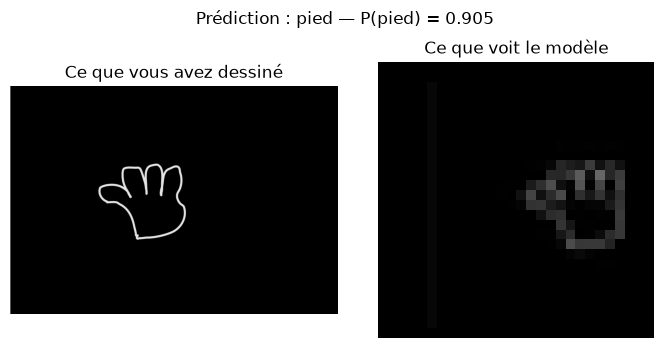

{'label': 'pied', 'probability': 0.9046161469709889, 'class1_name': 'pied'}

In [63]:
# Exemple avec une image externe :
my_img = load_png_as_bitmap("main.png")
classify_my_bitmap(my_img)

### 6.1 Bilan

Revenez à votre réponse de la Question préambule section 1,
après avoir comparé avec les autres groupes vos accuracies et types d'erreurs. 
**Question**  Quel couple semble le mieux séparé par un modèle linéaire ?
